# Confusion Matrix

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

A grid of actual versus predicted classes. The diagonal holds correct predictions, and every off-diagonal cell shows a specific kind of mistake.

## When to use

- Show which classes a classifier confuses with each other
- Report sensitivity and specificity per class for a diagnostic test
- Show agreement between two raters or two methods on categorical labels

## Avoid when

- There are dozens of classes (aggregate, or show only the top confusions)
- You need threshold-free performance (use ROC or PR curves)

## Alternatives

- Per-class precision/recall bar chart
- Sankey from actual to predicted

## Design tips

- Color by row-normalised percentage (recall) but print both count and percentage
- Use a one-hue sequential scale and switch to white text on dark cells

## Example

A classifier assigning breast-cancer molecular subtypes (synthetic predictions, 600 cases).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.metrics import confusion_matrix

### Data

In [2]:
rng = np.random.default_rng(10)
classes = ["Luminal A", "Luminal B", "HER2-enriched", "Basal-like"]
# row = true class; probabilities of each predicted class
P = np.array([[0.86, 0.11, 0.02, 0.01],
              [0.18, 0.72, 0.08, 0.02],
              [0.03, 0.09, 0.84, 0.04],
              [0.01, 0.02, 0.05, 0.92]])
n = [240, 150, 90, 120]
y_true = np.repeat(np.arange(4), n)
y_pred = np.concatenate([rng.choice(4, size=k, p=P[i]) for i, k in enumerate(n)])
cm = confusion_matrix(y_true, y_pred)
model_name = "Subtype classifier"
pd.DataFrame(cm, index=[f"true {c}" for c in classes], columns=[f"pred {c}" for c in classes])

,pred Luminal A,pred Luminal B,pred HER2-enriched,pred Basal-like
true Luminal A,209,25,6,0
true Luminal B,27,107,14,2
true HER2-enriched,4,9,73,4
true Basal-like,0,3,6,111


### Plot

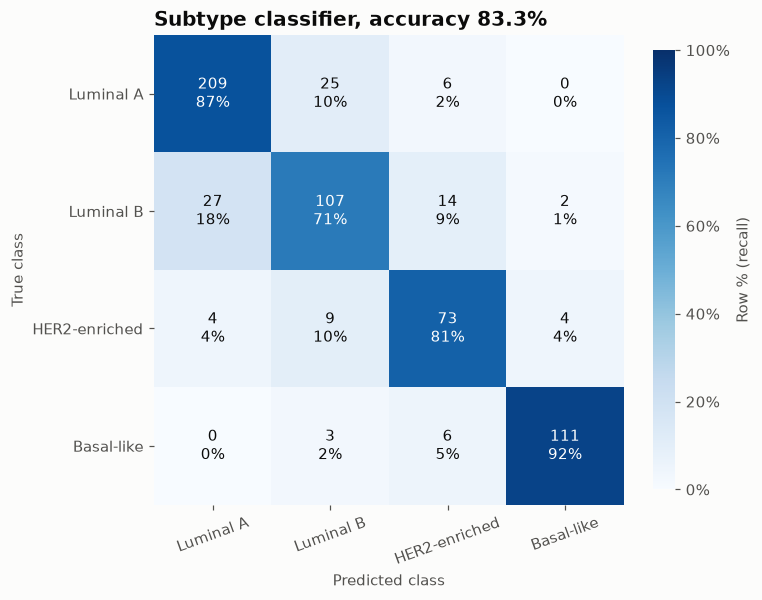

In [3]:
pct = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pct, cmap=SEQ_CMAP, vmin=0, vmax=1)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=10,
                color="white" if pct[i, j] > 0.55 else "#0b0b0b")
ax.set_xticks(range(len(classes)), classes, rotation=20); ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8, format=lambda v, _: f"{v:.0%}")
cb.set_label("Row % (recall)"); cb.outline.set_visible(False)
ax.set_title(f"{model_name}, accuracy {np.trace(cm) / cm.sum():.1%}")
fig.tight_layout()
plt.show()

## How to read it

Each row is a true class, and the diagonal shows the share classified correctly. The biggest error is Luminal B predicted as Luminal A (row 2, column 1).

## Try it with real data

**Source:** sklearn.datasets.load_breast_cancer() — Wisconsin diagnostic breast cancer, 569 tumours (malignant = positive), bundled with scikit-learn

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
bc = load_breast_cancer()
X_tr, X_te, y_tr, y_te = train_test_split(bc.data, bc.target, test_size=0.4, random_state=0,
                                          stratify=bc.target)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
classes = ["Malignant", "Benign"]                   # target 0 = malignant, 1 = benign
y_true, y_pred = y_te, clf.predict(X_te)
cm = confusion_matrix(y_true, y_pred)
model_name = "Breast-cancer classifier (logistic regression)"
pd.DataFrame(cm, index=[f"true {c}" for c in classes], columns=[f"pred {c}" for c in classes])

,pred Malignant,pred Benign
true Malignant,82,3
true Benign,5,138


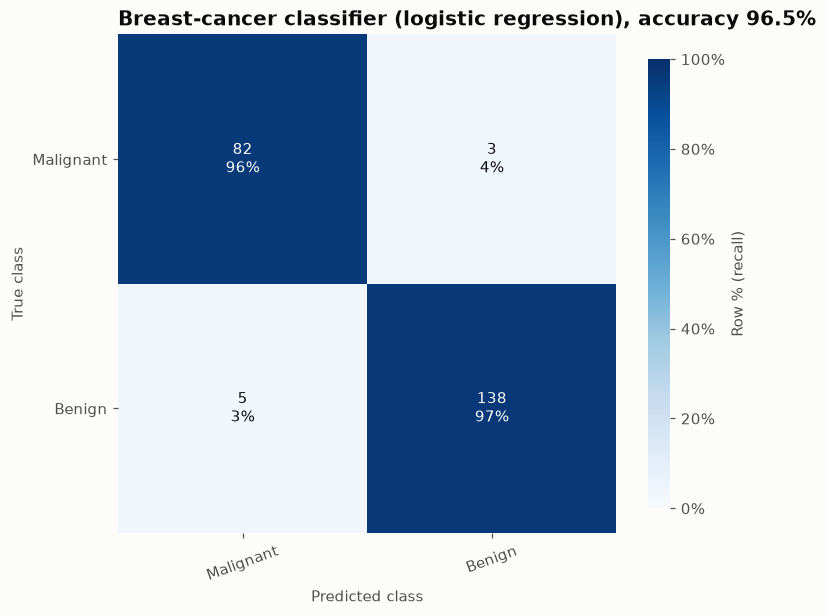

In [5]:
pct = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pct, cmap=SEQ_CMAP, vmin=0, vmax=1)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=10,
                color="white" if pct[i, j] > 0.55 else "#0b0b0b")
ax.set_xticks(range(len(classes)), classes, rotation=20); ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8, format=lambda v, _: f"{v:.0%}")
cb.set_label("Row % (recall)"); cb.outline.set_visible(False)
ax.set_title(f"{model_name}, accuracy {np.trace(cm) / cm.sum():.1%}")
fig.tight_layout()
plt.show()

---
Standalone script: [`confusion_matrix.py`](confusion_matrix.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)